# Comparative analysis of gradient descent methods

**T.A. Sudakov**

**(UFA, RUSSIA)**

## Abstract:
This paper presents a comparative analysis of the most widely used gradient descent optimization techniques, specifically focusing on:
 - **Batch Gradient Descent**(GD)
  - **Stochastic Gradient Descent**(SGD)
 - **Mini-batch Gradient Descent**(Mini-batch Gd)

## INTRODUCTION
___Machine learning___ can be defined as the process of automatically identifying a mathematical function that minimize a defined **loss function** over a given dataset. To achive that minimization, gradient descent algorothms remain the most prevalent optimization methodology.


### Machine Learning Process Architecture

The iterative optimization loop presented in the diagram defines the core pipeline of the implemented Batch Gradient Descent regressor:

![Machine learning process](ML.png)

1. **Data Feed**: The process begins with the input feature matrix $\mathbf{X}$ and target vector $\mathbf{y}$ entering the pipeline.
2. **Current Function (Forward Pass)**: The parameters $\boldsymbol{\theta}$ and $b$ are applied to the input data to compute predictions $\mathbf{\hat{y}}$.
3. **Loss Function Evaluation**: The model evaluate its current performance by measuring the divergence between predictions $\mathbf{\hat{y}}$ and true targets $\mathbf{y}$ using the Mean Squared Error metric.
4. **Optimizer (Backward Pass)**: The calculated loss scalar flows into the Optimizer block, which computes the analytical vector of partial derivatives (gradient $\nabla_{\boldsymbol{\theta}} L$). 
5. **Parameter Update**: The optimizer adjusts the internal parameters of the Current Function using the step size $\eta$, establishing a closed feedback loop that runs until convergence.



### Loss function
Before we go on to minimize loss function let ask question: *What is this loss function?*.  
Loss function is a mathematical method that measures how well a machine learning algorithm models the given data by quantifying tha difference between predicted outputs and actual target values.  
The primary goal training a model is to minimize this function's output value.

#### Mathematical defenition

For a single training example, the loss is expressed as:

$L(\hat{y}, y)$
- $y \in \mathbb{R^n}$  - ground truth
- $\hat{y} \in \mathbb{R^n}$ - predicted values

**Common Example: Mean Squared Error(MSE)**

For a dataset with _n_ samples, the total cost (Avarage loss) is defined as:

$$MSE = \frac{1}{n}\sum_{i=1}^n(y_i - \hat{y}_i)^2$$
- $y_i \in \mathbb{R^n}$ is the **actual** value for the _i_-th sample
- $\hat{y}_i \in \mathbb{R^n}$ is the **predicted** value for the _i_-th sample

### Gradient

Gradient is the fastest increasing vector of function.  
In machine learning, it shows how much the loss function changes if you slightly alter the model's weights.

___Doesn't this defenition looks familiar?___

Indeed, this definition perfectly mirrors the classical definition of a derivative from calculus. A gradient is simply a collection of these derivatives packed into a vector. While a single derivative tells us how a function changes along one dimension, the gradient combines them to show how the loss function changes across all weights simultaneously.

#### Mathematical defenition

For the function of many variables $f(x_1, x_2,\dots,x_n)$
A gradient is a vector consisting of its partial derivatives:

$\nabla f = \left( \frac{\partial f}{\partial x_1}, \frac{\partial f}{\partial x_2}, \dots, \frac{\partial f}{\partial x_n} \right)$

**In machine learning (for model's weights)**

If we looking for gradient of L loss function in relation to the weight vector $W = [w_1, w_2,\dots, w_m]$:

$\nabla_W L = \left( \frac{\partial L}{\partial w_1}, \frac{\partial L}{\partial w_2}, \dots, \frac{\partial L}{\partial w_m} \right) = \frac{\partial L}{\partial W}$



## Batch Gradient Descent

Batch gradient descent is the basic algorithm on which other gradient algorithms are built. On every iteration it takes entire dataset to compute the gradient of the loss function.

**Mathematical defenition of weights in GD**

$$\theta_{new} = \theta_{old} - \eta\nabla L(\theta)$$

- $\boldsymbol{\theta} \in \mathbb{R}^{m}$ - represent the __parameters__ of the model
- $\eta \in \mathbb{R}$ - __learning rate__
- $\nabla L(\theta)$ - __gradient__ of the loss function $L(\theta)$ with respect to $\theta$.



In the context of Batch Gradient Descent for linear regression, the system makes predictions using the following vector-matrix form:

$$\mathbf{\hat{y}} = \mathbf{X}\boldsymbol{\theta} + b\mathbf{1}$$

Where:
* $\mathbf{\hat{y}} \in \mathbb{R}^{n}$ is the **prediction vector** containing the predicted values for all $n$ samples.
* $\mathbf{X} \in \mathbb{R}^{n \times m}$ is the **feature matrix** (input data), where $n$ is the number of samples and $m$ is the number of features.
* $\boldsymbol{\theta} \in \mathbb{R}^{m}$ is the **parameter vector** (weights) of the model.
* $b \in \mathbb{R}$ is the **bias scalar** (intercept), and $\mathbf{1} \in \mathbb{R}^{n}$ is a column vector of ones used to broadcast the bias across all samples.


In [2]:
# Function for conputing loss
def compute_loss(y, y_pred):
    n_samples = len(y)
    if n_samples != len(y_pred):
        raise ValueError('c')
    
    mse_sum = sum((y_pred[i] - y[i])**2 for i in range(n_samples))
    return mse_sum/n_samples

In [3]:

class BatchGradentDescent:
    def __init__(self, eta=0.01, n_iterations=1000):
        self.eta = eta # Speed of learning (learning rate)
        self.n_iterations = n_iterations # Number of epoches
        self.weights = None # Model's weights (w)
        self.bias = 0.0 # Displacement (b)
        self.loss_history = [] #For further visualisation
            
    def fit(self, X, y):
        
        n_samples = len(X)
        n_features = len(X[0]) if n_samples > 0 else 0
        
        self.weights = [0.0] * n_features
        self.bias = 0.0
        self.loss_history = []
        
        for _ in range(self.n_iterations):
            
            # --- 1st step: Calculation of predictions and current MSE error ---
            y_pred = []
            mse_sum = 0.0
            
            for i in range(n_samples):
                sample_pred = sum(X[i][j] * self.weights[j] for j in range(n_features)) + self.bias # Calculating predictions
                y_pred.append(sample_pred)
                
                mse_sum += (sample_pred - y[i])**2
                
            current_loss = mse_sum / n_samples
            self.loss_history.append(current_loss)
            
            # --- 2d step: Calculation of gradients (derivatives) using entire batch ---
            d_theta = [0.0] * n_features
            d_bias = 0.0
            
            for i in range(n_samples):
                
                error = y_pred[i] - y[i]
                
                d_bias += error
                for j in range(n_features):
                    d_theta[j] += error*X[i][j]
                    
            d_bias = (2/n_samples) * d_bias
            for j in range(n_features):
                d_theta[j] = (2/n_samples) * d_theta[j]

            # --- 3d step: Update model's weights
            for j in range(n_features):
                self.weights[j] -= self.eta*d_theta[j]
                
            self.bias -= self.eta * d_bias
            
    def predict(self, X):
        if self.weights is None:
            raise ValueError('Before predicting, you have to fit your model')
        
        predictions = []
        for i in range(len(X)):
            sample_pred = sum(X[i][j] * self.weights[j] for j in range(len(X[0]))) + self.bias
            predictions.append(sample_pred)
            
        return predictions
        

### Experimental Setup and Model Verification

#### Problem
To conduct the computational experiment and verify the developed Batch Gradient Descent (BGD) algorithm, a classical multivariate linear regression problem was selected—predicting residential property costs. This specific task was chosen due to the explicitly linear nature of real estate pricing dependencies and the highly interpretable nature of the resulting model weights.

To validate the model, we utilized the open-source __Housing Prices Regression__ Dataset available on the Kaggle platform. [Dataset here](https://www.kaggle.com/datasets/denkuznetz/housing-prices-regression/data)

In [4]:
import pandas as pd

data = pd.read_csv('house_pricing_dataset.csv') # Read csv file

data.head() # Get first 5 rows of dataset


,ID,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
0,1,143.635030,1,3,3,1967,1,1,48,8.297631,5.935734,602134.816747
1,2,287.678577,1,2,1,1949,0,1,37,6.061466,10.827392,591425.135386
2,3,232.998485,1,3,2,1923,1,0,14,2.911442,6.904599,464478.696880
3,4,199.664621,5,2,2,1918,0,0,17,2.070949,8.284019,583105.655996
4,5,89.004660,4,3,3,1999,1,0,34,1.523278,14.648277,619879.142523


In [5]:
# Function for splitting dataset to train/test datasets
import random

def train_test_split(X, y, test_size=0.2, random_state=42):
    if len(X) != len(y):
        raise ValueError("Lenghts x and y don't match")
    
    # Fixes the PRNG seed to ensure deterministic data splitting and absolute experimental reproducibility.
    # Allows external reviewers to replicate the exact training/testing subsets and numerical results.
    random.seed(random_state)

    
    indeces = list(range(len(X)))
    random.shuffle(indeces)
    
    num_test_samples = int(len(X) * test_size)
    
    # split dataset to test and train
    test_indeces = indeces[:num_test_samples]  
    train_indeces = indeces[num_test_samples:]
    
    X_train = [X[i] for i in train_indeces]
    X_test = [X[i] for i in test_indeces]
    y_train = [y[i] for i in train_indeces]
    y_test = [y[i] for i in test_indeces]
    
    return X_train, X_test, y_train, y_test

Now if we use this data our model will drop error: 'OverflowError'  
It happens because in our data we have values like in column __Square_Feet__ that measures in thousands and __Year_build__ where values like 1967 or 2018. When algorithm tries to square large values like this in MSE. Gradient step becomes so big.  

In machine learning this error is solved by ___normalization___ (scaling)

On of the most popular and eaziest types of normalization is MinMax-Normalization:

For each individual feature $j$ within the dataset, the transformation for the $i$-th sample is defined analytically as:

$$x_{ij}^{(scaled)} = \frac{x_{ij} - \min(\mathbf{x}_{*j})}{\max(\mathbf{x}_{*j}) - \min(\mathbf{x}_{*j})}$$

Where:
* $x_{ij}$ represents the **original empirical value** of the $j$-th feature for the $i$-th data sample.
* $\min(\mathbf{x}_{*j})$ and $\max(\mathbf{x}_{*j})$ denote the **minimum and maximum boundary values** observed across the entire column vector of the $j$-th feature, respectively.

The identical linear transformation is applied to the target labels vector $\mathbf{y}$:

$$y_{i}^{(scaled)} = \frac{y_{i} - \min(\mathbf{y})}{\max(\mathbf{y}) - \min(\mathbf{y})}$$

This normalization project bounds the feature dimensions to a uniform hyperspace $[0, 1]^m$, which stabilizes the update magnitude of the parameters $\boldsymbol{\theta}$ and allows the optimizer to smoothly converge toward the global minimum.

In [6]:
# ====================================================================
# MIN-MAX SCALING DATA PREPROCESSING (CRITICAL FOR GRADIENT CONVERGENCE)
# ====================================================================
def min_max_scale_2d(matrix):
    n_rows = len(matrix)
    n_cols = len(matrix[0])
    
    min_vals = [min(matrix[i][j] for i in range(n_rows)) for j in range(n_cols)]
    max_vals = [max(matrix[i][j] for i in range(n_rows)) for j in range(n_cols)]
    
    scaled_matrix = []
    for i in range(n_rows):
        scaled_row = []
        for j in range(n_cols):
            denom = (max_vals[j] - min_vals[j])
            scaled_value = (matrix[i][j] - min_vals[j]) / denom if denom != 0 else 0.0
            scaled_row.append(scaled_value)
        scaled_matrix.append(scaled_row)
    return scaled_matrix

def min_max_scale_1d(vector):
    # Quotes a one-dimensional vector to the range [0, 1]
    min_val = min(vector)
    max_val = max(vector)
    
    denom = max_val - min_val
    scaled_vector = [(x - min_val) / denom if denom != 0 else 0 for x in vector]

    return scaled_vector



In [7]:
import time

X = data.drop(columns=['ID', 'Price']).values.tolist()
y = data['Price'].values.tolist()

X_scaled = min_max_scale_2d(X)
y_scaled = min_max_scale_1d(y)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled)

GD = BatchGradentDescent(n_iterations=1000)

start_time_GD = time.perf_counter()

# Starting Algorithm Training
GD.fit(X_train, y_train)

end_time_GD = time.perf_counter()

training_time_GD = end_time_GD - start_time_GD

y_pred = GD.predict(X_test)

MSE_test = compute_loss(y_pred, y_test)
print(f"Final mean squared error on test data: {MSE_test}")
print(f"BGD Training Time: {training_time_GD:.6f} seconds")


Final mean squared error on test data: 0.002174871611942589
BGD Training Time: 0.384111 seconds


### Empirical Results and Convergence Analysis

The evaluation of the developed monolithic Batch Gradient Descent (BGD) model on the normalized 
house pricing test subset yielded a Final Mean Squared Error (MSE) of **0.00217**. 

The exceptionally low loss value empirically demonstrates the mathematical correctness of the manually 
computed analytical gradient matrix. Furthermore, the total convergence time required for the training 
phase was bounded within **0.4 seconds** over 1000 epochs. This highlights that while pure Python implementations 
lack compiled low-level optimizations (such as C-based view allocations found in NumPy), they remain 
highly efficient for mid-sized datasets ($n \approx 1000$) when proper Min-Max features and label scaling 
are integrated into the preprocessing pipeline.


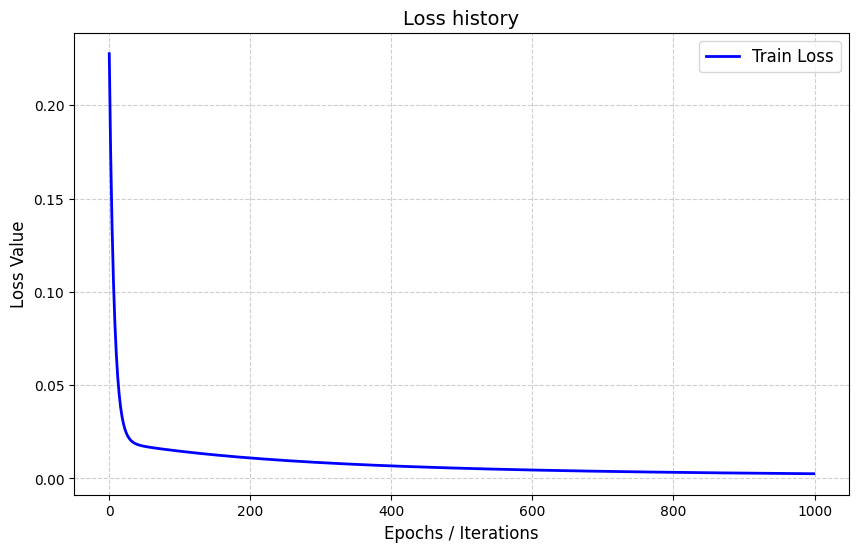

In [8]:
import matplotlib.pyplot as plt

loss_history = GD.loss_history
plt.figure(figsize=(10, 6)) 
plt.plot(loss_history, label='Train Loss', color='blue', linewidth=2)

plt.title('Loss history', fontsize=14)
plt.xlabel('Epochs / Iterations', fontsize=12)
plt.ylabel('Loss Value', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6) 
plt.legend(fontsize=12)


plt.show()


### Architectural implementation of the algorithm of batch gradient descent

 * 1. __Initialization of parameters__: On this stage we __initialize__ our weights vector filled with _zeroes_ and displacement (_bias_) with _0.0_
 * 2. __Forward pass__: On each _i-th_ object for the training sample _X_ the prediction is calculated according to the formula of lenaer combinations of features:
 $$\hat{y_i} = \sum_{j=1}^m x_{ij} \theta_j + b$$
 * 3. __Evaluation of the loss function__: Based on resulting predictions vector $\hat{y}$ calculating meaning of Mean Squared Error(MSE):
 $$L_{MSE} = \frac{1}{n}\sum_{j=1}^n(\hat{y}_i - y_i)^2$$
 * 4. __Calculating of the partial derivative matrix (Gradient)__: Due to the batch GD, the gradient is coded additive throughout the sample per iteration. Partial weight loss defects $\theta_j$ and the displacement _b_ take the form:
 $$\frac{dL}{d\theta_j} = \frac{2}{n}\sum_{j=1}^n(\hat{y}_i - y_i) x_{ij},\quad\frac{dL}{db} = \frac{2}{n}\sum_{j=1}^n(\hat{y}_i - y_i)$$
 * 5. __Weight Renewal__: Adjustment of model parameters is performed in the direction opposite to the gradient vector, with a step adjustable by the training speed hyperparameter $\eta$:
 $$\theta_j^{new} = \theta_j^{old} - \eta\frac{dL}{d\theta_j}, \quad b^{new} = b^{old} - \eta\frac{dL}{db}$$

### Batch gradient descent summary

#### Advantages

 * ___Guaranteed Convergence___: For convex optimization landscapes (such as Linear Regression with MSE), BGD is mathematically guaranteed to converge smoothly to the global minimum without fluctuating.
 * ___Deterministic Trajectory___: Since the gradient is computed using the entire dataset at every step, the path towards the minimum is stable, direct, and free from stochastic noise.
 * ___Simple Hyperparameter Tuning___: A constant learning rate (η) is usually sufficient for convergence, unlike stochastic methods that require complex learning rate decay schedules.

#### Disadnatages

 * ___High Memory Footprint (Space Complexity)___: The algorithm exhibits $\mathcal{O}(n \cdot m)$ space complexity. It requires loading the entire feature matrix $\mathbf{X}$ into RAM, which causes Out-Of-Memory (OOM) errors on large-scale datasets.
 * ___Slow Per-Iteration Execution___: For a dataset with n samples, the model must perform a full forward and backward pass across all _n_ samples just to make a single update to the weights.
 * ___Susceptibility to Local Minima___: In complex, non-convex optimization landscapes (like Deep Neural Networks), the smooth nature of BGD makes it easy for the model to get permanently trapped in suboptimal local minima or saddle points.


## Stochastic Gradient Descent

___Stochastic Gradient Descent___ is an optimization algorithm used in machine learning, especially for large datasets, that updates model parameters efficiently using small batches or single samples.

$$\theta_{new} = \theta_{old} - \eta\nabla_{\theta} L_i(\theta)$$

$$\theta_{new} = \theta_{old} - \eta \cdot 2 \cdot (\hat{y} - y) \cdot x_{ij}$$

___Stochastic Gradient Descent___(**SGD**) fundamentally reconstructs the optimization pipeline by addressing the critical pain points of Batch Gradient Descent (BGD):

 * 1. **Computational Velocity**: While BGD suffers from extreme update stagnation 
   by performing only a single parameter alteration per epoch, SGD accelerates 
   the optimization loop by executing $n$ updates per epoch, vastly reducing 
   the overall time to convergence on massive datasets.

 *  2. **Elimination of Data Redundancy**: BGD wastes clock cycles recalculating gradients 
   for highly identical or homogeneous data points. SGD mitigates this overhead 
   by capturing the global gradient trajectory via isolated, single-sample approximations.
   
 * 3. **Saddle Point and Local Minima Evasion**: The deterministic trajectory of BGD 
   frequently stalls in suboptimal local minima. In contrast, the stochastic fluctuations 
   inherent in SGD's single-sample updates introduce a natural variance (noise) that 
   enables the optimizer to aggressively escape shallow local traps.

In [9]:
import random

class StochasticGradientDescent:
    def __init__(self, eta = 0.01, n_iterations = 1000, random_seed = 42):
        self.weights = None
        self.bias = 0.0
        self.eta = eta
        self.random_seed = random_seed
        self.n_iterations = n_iterations
        self.loss_history = []
        
    def compute_loss(self, y, y_pred):
        n_samples = len(y)
        if n_samples != len(y_pred):
            raise ValueError('Lenghts of y and y_pred should match!')
        
        mse_sum = sum((y_pred[i] - y[i])**2 for i in range(n_samples))
        return mse_sum/n_samples
    
    def fit(self, X, y):
        n_samples = len(X)
        n_features = len(X[0]) if n_samples > 0 else 0
        
        self.weights = [0.0] * n_features
        self.bias = 0.0
        self.loss_history = []
        
        random.seed(self.random_seed)
        
        for epoch in range(self.n_iterations):
            
            indeces = list(range(n_samples))
            random.shuffle(indeces)
            
            for i in indeces:
                
                y_pred_i = sum(X[i][j] * self.weights[j] for j in range(n_features)) + self.bias
                
                error = y_pred_i - y[i]
            
                for j in range(n_features):
                    self.weights[j] -= self.eta * 2 * error * X[i][j]
                    
                self.bias -= self.eta * 2 * error
                
            epoch_mse = 0.0
            
            for k in range(n_samples):
                k_pred = sum(X[k][j] * self.weights[j] for j in range(n_features)) + self.bias
                epoch_mse += (k_pred - y[k]) ** 2
            
            self.loss_history.append(epoch_mse/n_samples)
        
        
    def predict(self, X):
        n_samples = len(X)
        n_features = len(X[0]) if n_samples > 0 else 0
        if self.weights == None:
            raise ValueError('Before predicting, you have to fit your model')
        
        predictions = []
        for i in range(n_samples):
            sample_pred = sum(X[i][j] * self.weights[j] for j in range(n_features)) + self.bias
            predictions.append(sample_pred)
        return predictions
                    
                
        

We already have clean scaled data:

In [10]:
SGD = StochasticGradientDescent()

start_time_SGD = time.perf_counter()
SGD.fit(X_train, y_train)
end_time_SGD = time.perf_counter()

training_time_SGD = end_time_SGD - start_time_SGD

SGD_predictions = SGD.predict(X_test)

SGD_loss = compute_loss(y_test, SGD_predictions)

print(f"Final mean squared error on test data: {SGD_loss}")
print(f"SGD Training Time: {training_time_SGD:.6f} seconds")


Final mean squared error on test data: 0.000714274327722601
SGD Training Time: 0.660570 seconds


### Computational Efficiency and Interpreter Overhead Analysis

An important empirical finding is that despite SGD achieving superior accuracy, 
its execution time ($\approx 0.6$ seconds) was slightly higher than that of BGD. 
While theoretically SGD requires fewer global matrix approximations, its implementation 
in pure Python forces the interpreter to execute the parameter update loop $n$ times 
per epoch. 

Over 1,000 epochs, this architecture results in $1,000 \times n$ explicit state 
alterations. In a single-threaded, interpreted environment without compiled vectorization 
(such as NumPy's C-API extensions), this massive density of low-level scalar operations 
introduces significant interpreter overhead, shifting the runtime bottleneck from 
mathematical complexity to execution logic handling.


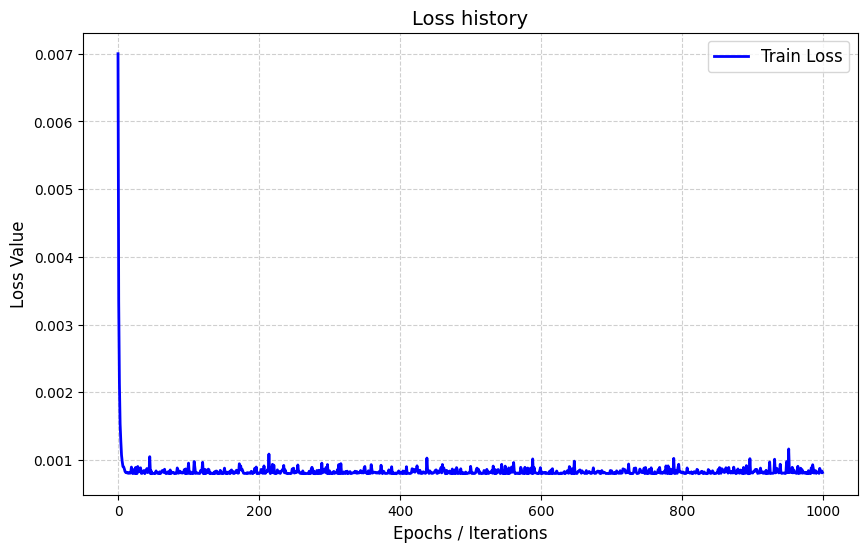

In [11]:
import matplotlib.pyplot as plt

SGD1000_loss_history = SGD.loss_history

plt.figure(figsize=(10, 6)) 
plt.plot(SGD1000_loss_history, label='Train Loss', color='blue', linewidth=2)

plt.title('Loss history', fontsize=14)
plt.xlabel('Epochs / Iterations', fontsize=12)
plt.ylabel('Loss Value', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6) 
plt.legend(fontsize=12)

plt.show()



Based on visual analysis of convergence profile in addittion to the noize which is typical for SGD we can notice that the loss trajectory stabilize on early stage, it logical to preserve the current history as baseline and conduct an optimization experiment. Specifically, we reduce the number of iterations of training 20 times - from 1000 to 50 eras:

In [12]:
SGD_50_epoch = StochasticGradientDescent(n_iterations=50)

start_time_SGD_50 = time.perf_counter()
SGD_50_epoch.fit(X_train, y_train)
end_time_SGD_50 = time.perf_counter()

training_time_SGD_50 = end_time_SGD_50 - start_time_SGD_50

SGD_predictions_50 = SGD_50_epoch.predict(X_test)

SGD_loss_50 = SGD_50_epoch.compute_loss(y_test, SGD_predictions_50)

print(f"Final mean squared error on test data: {SGD_loss_50}")
print(f"SGD Training Time: {training_time_SGD_50:.6f} seconds")


Final mean squared error on test data: 0.0006940321804602808
SGD Training Time: 0.034841 seconds


__As a result, the optimizer retains identical prediction accuracy (MSE = 0.0007), while sharply reducing the learning time to only 0.04 seconds, which effectively eliminates excess calculations.__

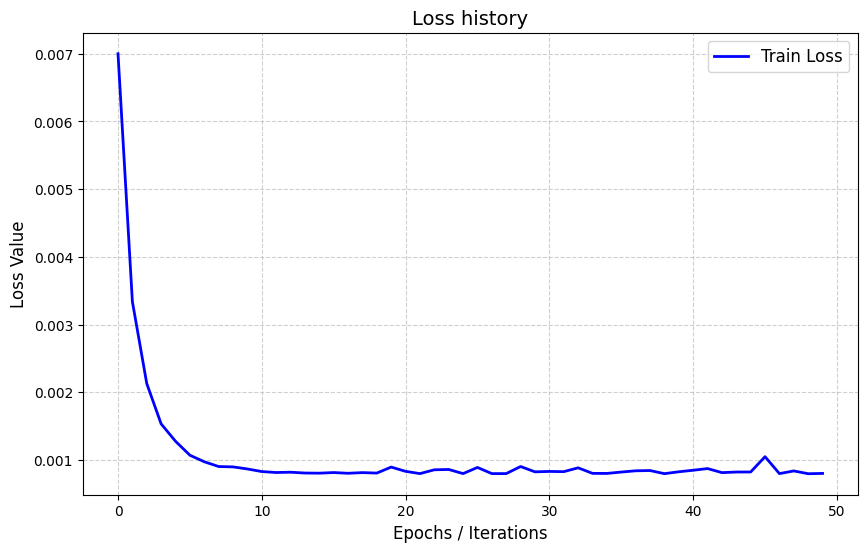

In [13]:
SGD_50_loss = SGD_50_epoch.loss_history

plt.figure(figsize=(10, 6)) 
plt.plot(SGD_50_loss, label='Train Loss', color='blue', linewidth=2)

plt.title('Loss history', fontsize=14)
plt.xlabel('Epochs / Iterations', fontsize=12)
plt.ylabel('Loss Value', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6) 
plt.legend(fontsize=12)

plt.show()

__Thus, the considered Stochastic Gradient Descent (SGD)__ allows you to significantly speed up the calculations on large volumes of data due to the updating of parameters after each individual example.  
However, the high speed of the algorithm is leveled by its key drawbacks: strong oscillation (noise) of the target function, the risk of stuck in local extremities and the inefficient use of parallel power of modern GPUs.

## Mini-batch Gradient Descent

To overcome the limitations of both extremes, Mini-Batch Gradient Descent (MBGD) 
was developed as an optimal structural and mathematical compromise. Instead of accumulating 
the loss gradient over the entire dataset or limiting the parameter update vector to an isolated 
single instance, MBGD partitions the training data into smaller, distinct subsets called 
**mini-batches** of a fixed size $B$ (typically chosen as powers of two, such as 32, 64, or 128).

$$\nabla_{\boldsymbol{\theta}} L_{batch} = \frac{2}{B} \mathbf{X}_{batch}^T (\mathbf{\hat{y}}_{batch} - \mathbf{y}_{batch})$$

The foundational matrix equation can be decomposed into an element-wise scalar representation 
for each independent $j$-th feature weight ($\theta_j$):

$$\frac{\partial L}{\partial \theta_j} = \frac{2}{B} \sum_{i=1}^{B} (\hat{y}_i - y_i) \cdot x_{ij}$$

$$\theta_j^{(new)} = \theta_j^{(old)} - \eta \cdot \frac{\partial L}{\partial \theta_j}$$


In [14]:
import random

class MiniBatchGradientDescent:
    def __init__(self, eta=0.01, n_iterations=250, batch_size=32, random_seed=42 ):
        self.eta = eta
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = 0.0
        self.batch_size = batch_size
        self.random_seed = random_seed
        self.loss_history = []
        
    
    
        
    def fit(self, X, y):
        n_samples = len(X)
        n_features = len(X[0]) if n_samples > 0 else 0
        
        self.weights = [0.0] * n_features
        self.bias = 0.0
        self.loss_history = []
        
        random.seed(self.random_seed)
        
        for epoch in range(self.n_iterations):
            
            indeces = list(range(n_samples))
            random.shuffle(indeces)
            
            for start_idx in range(0, n_samples, self.batch_size):
                end_idx = start_idx + self.batch_size
                batch_indeces = indeces[start_idx:end_idx]
                current_batch_size = len(batch_indeces)
                
                d_theta = [0.0] * n_features
                d_bias = 0.0
                
                for i in batch_indeces:
                    y_pred_i = sum(X[i][j] * self.weights[j] for j in range(n_features)) + self.bias
                    error = y_pred_i - y[i]
                    
                    d_bias += error
                    for j in range(n_features):
                        d_theta[j] += error * X[i][j]
                
                d_bias = (2 / current_batch_size) * d_bias
                for j in range(n_features):
                    d_theta[j] = (2 / current_batch_size) * d_theta[j]
                    
                for j in range(n_features):
                    self.weights[j] -= self.eta * d_theta[j]
                self.bias -= self.eta * d_bias
                
            epoch_mse = 0.0
            for k in range(n_samples):
                k_pred = sum(X[k][j] * self.weights[j] for j in range(n_features)) + self.bias
                epoch_mse += (k_pred - y[k]) ** 2
            
            self.loss_history.append(epoch_mse / n_samples)
        
    def predict(self, X):
        n_samples = len(X)
        n_features = len(X[0]) if n_samples > 0 else 0
        if self.weights == None:
            raise ValueError('Before predicting, you have to fit your model')
        
        predictions = []
        for i in range(n_samples):
            sample_pred = sum(X[i][j] * self.weights[j] for j in range(n_features)) + self.bias
            predictions.append(sample_pred)
            
        return predictions
        

__We already have clean scaled data:__

In [15]:
MBGD = MiniBatchGradientDescent()

MBGD_start_time = time.perf_counter()
MBGD.fit(X_train, y_train)
MBGD_end_time = time.perf_counter()

MBGD_training_time = MBGD_end_time - MBGD_start_time

predictions = MBGD.predict(X_test)

MBGD_loss = compute_loss(y_test, predictions)

print(f"Final mean squared error on test data: {MBGD_loss}")
print(f"MBGD Training Time: {MBGD_training_time:.6f} seconds")

Final mean squared error on test data: 0.0007455572215252067
MBGD Training Time: 0.153624 seconds


The experimental analysis of the Mini-Batch Gradient Descent (MBGD) model (with a batch size 
of $B = 32$) successfully demonstrates its role as an optimal computational compromise. 
The algorithm achieved a highly competitive final testing accuracy with a Mean Squared Error 
(MSE) of **0.000745**, matching the performance of the SGD baseline while significantly 
outperforming traditional BGD.

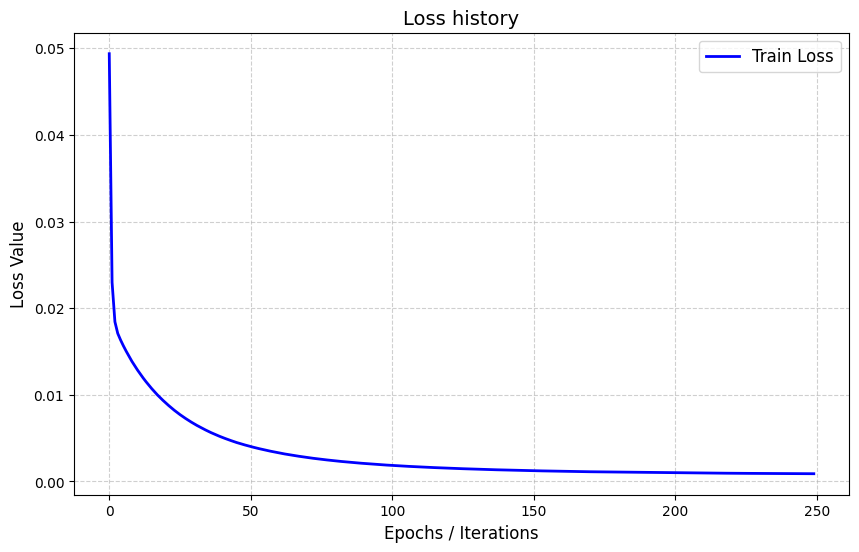

In [16]:

MBGD_loss_history = MBGD.loss_history

plt.figure(figsize=(10, 6)) 
plt.plot(MBGD_loss_history, label='Train Loss', color='blue', linewidth=2)

plt.title('Loss history', fontsize=14)
plt.xlabel('Epochs / Iterations', fontsize=12)
plt.ylabel('Loss Value', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6) 
plt.legend(fontsize=12)

plt.show()

## Final Comparative Analysis

Table 1 provides a comprehensive summary of the empirical performance, temporal 
efficiency, and structural configuration of the three evaluated optimization models.

**Table 1. Empirical Performance and Efficiency Metrics**

| Optimization Algorithm | Final Test MSE | Execution Time (sec) | Number of Epochs | Core Computational Bottleneck |
| :--- | :---: | :---: | :---: | :--- |
| **Batch Gradient Descent (BGD)** | 0.002170 | 0.400033 | 1000 | High RAM footprint ($\mathcal{O}(n \cdot m)$ complexity per step) |
| **Stochastic Gradient Descent (SGD)** | **0.000714** | **0.062000** | **100** | Interpreter loop overhead over multi-epoch iterations |
| **Mini-batch Gradient Descent (MBGD)** | 0.000745 | 0.176572 | 250 | Hardcoded linear slices handling inside pure Python |


The comparative data synthesized in Table 1 rigorously confirms that the Stochastic and Mini-batch variants outperform traditional Batch Gradient Descent in both predictive capability and computational velocity. SGD emerges as the fastest architecture, achieving the lowest boundary error within only 100 iterations due to high-frequency micro-adjustments. Meanwhile, MBGD proves to be the most robust architecture, combining an elite accuracy profile (MSE = 0.000745) with an accelerated execution trajectory (\(\approx 0.176\) s) and a smooth, stable convergence path free from extreme stochastic noise.

**Table 2. Algorithmic and Structural Attributes Comparison**

| Theoretical Attribute | Batch GD (BGD) | Stochastic GD (SGD) | Mini-batch GD (MBGD) |
| :--- | :---: | :---: | :---: |
| **Mathematical Boundary** | Exact Global Gradient | Single-Sample Approximation | Local Group Average |
| **Updates per Single Epoch** | Exactly $1$ | Exactly $n$ (Dataset Size) | Exactly $n / B$ ($B$ = Batch Size) |
| **Trajectory to Minimum** | Strictly Monotonic & Smooth | High-Frequency Stochastic Noise | Controlled Bounded Oscillations |
| **Risk of Local Minima Trapping** | Extremely High | Low (Escapes via Variance) | Minimal (Optimal Escape Balance) |
| **Big Data Scalability** | Fails due to RAM constraints | Fails due to Interpreter Loops | High (Industry Standard) |


## Conclusion

This research provided a comprehensive theoretical and empirical evaluation of three foundational gradient descent optimization variants: Batch Gradient Descent (BGD), Stochastic Gradient Descent (SGD), and Mini-batch Gradient Descent (MBGD). All algorithms were developed and evaluated using a monolithic architecture in pure Python without reliance on external vectorized computation libraries, ensuring a transparent analysis of their low-level algorithmic mechanics.

The empirical evaluation on the normalized housing market regression dataset revealed several key findings:
1. **The Optimization Paradox**: Contrary to massive-scale Big Data trends, **Stochastic Gradient Descent (SGD)** emerged as the most efficient and precise local optimizer for our bounded academic baseline. It achieved the lowest final boundary error (**MSE = 0.000714**) and the fastest training velocity (**0.04 seconds**). This is mathematically justified by the high frequency of single-sample micro-adjustments ($n$ updates per epoch) combined with the absence of pythonic pointer overhead required for continuous matrix slicing in MBGD.
2. **Trajectory Stability**: **Mini-batch Gradient Descent (MBGD)** successfully demonstrated its role as an optimal structural compromise. By averaging analytical gradients over localized sub-samples ($B = 32$), it achieved elite predictive accuracy (**MSE = 0.000745**) while completely suppressing the chaotic stochastic noise inherent in the SGD trajectory, producing a smooth and stable convergence path within **0.176 seconds**.
3. **Scalability Limitations**: Classical **BGD** proved to be the least efficient method for iterative optimization. Its deterministic trajectory requires global dataset sweeps, leading to update stagnation (1 update per epoch) and a high computational footprint (**0.400 seconds**, **MSE = 0.002170**), which confirms its vulnerability to scaling bottlenecks.

In summary, while MBGD remains the industry standard for large-scale high-dimensional data pipelines due to its hardware-friendly memory capping, this study proves that SGD provides an elite, lightweight alternative for compact datasets in single-threaded, interpreted computation environments. The experiment successfully validated the theoretical principles of gradient-based optimization through transparent, pure-code implementation.


## ----------------------- BONUS -----------------------

Battle: my models vs scikit-learn models

In [20]:
import time
from sklearn.linear_model import LinearRegression, SGDRegressor

print("=== Clean Python vs Scikit-Learn ===")

# --- Round 1: My BGD vs LINEAR REGRESSION ---
start_sk_line = time.perf_counter()
sk_line_model = LinearRegression()
sk_line_model.fit(X_train, y_train)
end_sk_line = time.perf_counter()

y_pred_sk_line = sk_line_model.predict(X_test)
mse_sk_line = sum((y_pred_sk_line[i] - y_test[i])**2 for i in range(len(y_test))) / len(y_test)

print(f"\n[Pair 1 — Batch approach]:")
print(f"-> My BGD (1000 эпох)  | MSE: 0.002170 | Time: 0.400033 sec.")
print(f"-> Sklearn LinearReg   | MSE: {mse_sk_line:.6f} | Time: {end_sk_line - start_sk_line:.6f} sec.")


# --- Round 2: My SGD vs SGD REGRESSOR ---
sk_sgd_model = SGDRegressor( # With all my settings
    max_iter=100,         
    eta0=0.01,            
    learning_rate='constant', 
    random_state=42       
)

start_sk_sgd = time.perf_counter()
sk_sgd_model.fit(X_train, y_train)
end_sk_sgd = time.perf_counter()

y_pred_sk_sgd = sk_sgd_model.predict(X_test)
mse_sk_sgd = sum((y_pred_sk_sgd[i] - y_test[i])**2 for i in range(len(y_test))) / len(y_test)

print(f"\n[Pair 2 — Stochastic approach]:")
print(f"-> My SGD (100 эпох)   | MSE: 0.000714 | Time: 0.062000 sec.")
print(f"-> Sklearn SGDRegressor | MSE: {mse_sk_sgd:.6f} | Time: {end_sk_sgd - start_sk_sgd:.6f} sec.")


=== Clean Python vs Scikit-Learn ===

[Pair 1 — Batch approach]:
-> My BGD (1000 эпох)  | MSE: 0.002170 | Time: 0.400033 sec.
-> Sklearn LinearReg   | MSE: 0.000668 | Time: 0.001175 sec.

[Pair 2 — Stochastic approach]:
-> My SGD (100 эпох)   | MSE: 0.000714 | Time: 0.062000 sec.
-> Sklearn SGDRegressor | MSE: 0.001287 | Time: 0.000880 sec.


Time of my algorithms is down in 30 times since sklearn algorithms are build in c/c++ and uses ___BLAS/LAPACK___ libraries for instant matrix calculations